# 🏠 Projet 1 — Prédire le prix des logements en Californie
---
## 🗺️ La « checklist » d'un projet ML

1. **Avoir une vue d'ensemble** du problème
2. **Récupérer les données**
3. **Créer un jeu de test** (et ne plus y toucher !)
4. **Explorer et visualiser** les données
5. **Préparer les données** pour les algorithmes
6. **Choisir et entraîner** des modèles
7. **Affiner** le meilleur modèle
8. **Évaluer** sur le jeu de test, puis **déployer et surveiller**

---
# Étape 1 — Avoir une vue d'ensemble 🔭

## 1.1 Cadrer le problème

**Le scénario du livre :** On est embauché dans une entreprise immobilière et on me donne les données
du **recensement californien de 1990**. Chaque ligne = un **district** (un petit quartier de 600 à 3 000 habitants).
Ma mission : construire un modèle qui **prédit le prix médian des maisons d'un district** à partir des autres
informations (revenu médian, population, localisation…).

Ma prédiction sera envoyée à **un autre système** qui décide s'il vaut la peine d'investir dans une zone.
Aujourd'hui, ce prix est estimé **à la main par des experts**, avec souvent **plus de 30 % d'erreur**.

### 🛠️ Ce qu'on en déduit
| Question | Réponse pour ce projet | Pourquoi |
|---|---|---|
| Supervisé ou non ? | **Supervisé** | On a des exemples **étiquetés** : pour chaque district on connaît le vrai prix (`median_house_value`). |
| Classification ou régression ? | **Régression** | On prédit un **nombre** (un prix), pas une catégorie. |
| Combien de variables d'entrée ? | **Régression multiple** | On utilise plusieurs caractéristiques (revenu, population…). |
| Combien de valeurs à prédire ? | **Univariée** | Une seule valeur par district : le prix. |
| Batch ou en ligne ? | **Apprentissage par lots (batch)** | Les données tiennent en mémoire et ne changent pas en continu. |

### 🔁 Alternatives et ⚖️ pourquoi pas
| Alternative | Quand c'est mieux | Pourquoi pas ici |
|---|---|---|
| **Classification** (prix « bas / moyen / élevé ») | Si le système en aval n'a besoin que d'une catégorie | Le système en aval veut **le prix réel**. On le demande *avant* : c'est une erreur classique de résoudre le mauvais problème ! |
| **Apprentissage en ligne** (*online learning*) | Données qui arrivent en flux continu, ou trop grosses pour la mémoire | ~20 000 lignes : ça tient largement en mémoire, rien n'arrive en flux. |
| **Pas de ML du tout** (règles manuelles) | Problème simple avec règles connues | Les experts font déjà ça… avec 30 % d'erreur. |

## 1.2 Choix d'une mesure de performance

### 🎯 Pourquoi ?
Pour savoir si un modèle est « bon », il faut **un chiffre** pour comparer les modèles entre eux.

### 🛠️ Méthode choisie : la RMSE (*Root Mean Squared Error*, racine de l'erreur quadratique moyenne)

$$\text{RMSE} = \sqrt{\frac{1}{m}\sum_{i=1}^{m}\left(\hat{y}^{(i)} - y^{(i)}\right)^2}$$

Pour chaque district, on calcule l'erreur (prédiction − vrai prix), on la met **au carré**,
on fait la **moyenne**, puis on prend la **racine carrée** pour revenir dans l'unité de départ (des dollars).

👉 Une RMSE de 50 000 signifie, en gros, « le modèle se trompe typiquement d'environ 50 000 $ ».

Le carré **punit beaucoup plus les grosses erreurs** : se tromper de 100 000 dollars une fois coûte autant que se tromper
de 10 000 dollars cent fois. C'est souvent ce qu'on veut (une énorme erreur d'investissement est grave).

### 🔁 Alternatives et ⚖️ pourquoi pas
| Métrique | Formule (idée) | Quand c'est mieux | Pourquoi pas ici |
|---|---|---|---|
| **MAE** (erreur absolue moyenne) | moyenne de \|erreur\| | Beaucoup de **valeurs aberrantes** (*outliers*) qu'on ne veut pas sur-pénaliser | Nos données ont peu d'outliers extrêmes, et on veut punir les grosses erreurs. |
| **MAPE** (erreur en %) | moyenne de \|erreur\| / vrai prix | Quand l'erreur **relative** compte (10 k$ d'erreur sur une maison à 50 k$ ≠ sur une à 500 k$) | Bonne idée en complément ! Mais la RMSE est la référence du livre et plus simple à optimiser. |
| **R²** | part de la variance expliquée (0 → 1) | Pour communiquer « le modèle explique 80 % des variations » | Sans unité : moins parlant qu'un montant en dollars pour comparer. |

## 1.3 Vérification des hypothèses
*le système en aval veut-il vraiment un prix ?* Dans le livre : **oui**. 
On part donc sur une régression. (S'il avait voulu des catégories, tout ce qui suit serait différent !)

---
# Étape 2 — Récupérer les données 📥

## 2.0 Mise en place de l'environnement

> **Installation**:
> ```bash
> pip install -r requirements.txt
> ```

On importe les bibliothèques et on vérifie leurs versions.

| Bibliothèque | Rôle |
|---|---|
| **NumPy** | Calcul numérique (tableaux, maths) |
| **pandas** | Manipuler des tableaux de données (`DataFrame`) — comme Excel en Python |
| **Matplotlib** | Faire des graphiques |
| **Scikit-Learn** (`sklearn`) | La boîte à outils du Machine Learning classique |
| **SciPy** | Outils scientifiques (distributions, statistiques) |

In [3]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
import scipy

print("Python      :", sys.version.split()[0])
print("NumPy       :", np.__version__)
print("pandas      :", pd.__version__)
print("Scikit-Learn:", sklearn.__version__)
print("SciPy       :", scipy.__version__)

# Scikit-Learn ≥ 1.6 est nécessaire (fonction root_mean_squared_error, API récente)
assert sklearn.__version__ >= "1.6", "Mets à jour scikit-learn : pip install -U scikit-learn"

# Graphiques un peu plus lisibles
plt.rc("font", size=12)
plt.rc("axes", labelsize=12, titlesize=13)

Python      : 3.15.2
NumPy       : 2.5.4
pandas      : 3.1.0
Scikit-Learn: 1.9.1
SciPy       : 1.18.1


### 🎲 Fixer le hasard (reproductibilité)

Beaucoup d'étapes utilisent du hasard (mélanger les données, initialiser un algorithme…).
On fixe une **graine** (`random_state=42`) pour obtenir **les mêmes résultats à chaque exécution**.
Sans ça, nos chiffres changeraient à chaque fois et on ne pourrait pas comparer deux essais.

In [4]:
RANDOM_STATE = 42
rng = np.random.default_rng(RANDOM_STATE)  # générateur aléatoire NumPy moderne

## 2.1 Téléchargement les données

In [5]:
import tarfile
import urllib.request

def load_housing_data():
    tarball_path = Path("datasets/housing.tgz")
    if not tarball_path.is_file():                      # déjà téléchargé ? on ne refait pas
        Path("datasets").mkdir(parents=True, exist_ok=True)
        url = "https://github.com/ageron/data/raw/main/housing.tgz"
        urllib.request.urlretrieve(url, tarball_path)   # téléchargement
    csv_path = Path("datasets/housing/housing.csv")
    if not csv_path.is_file():
        with tarfile.open(tarball_path) as housing_tarball:
            housing_tarball.extractall(path="datasets", filter="data")  # filter="data" = extraction sécurisée
    return pd.read_csv(csv_path)

housing_full = load_housing_data()
print("Dimensions :", housing_full.shape, "(lignes, colonnes)")

Dimensions : (20640, 10) (lignes, colonnes)


## 2.2 Premier coup d'œil à la structure des données

### 🎯 Pourquoi ?
Avant toute chose, il faut **connaître ses données** : combien de lignes, quels types, des valeurs manquantes ?
On va utiliser 4 outils de base de pandas : `head()`, `info()`, `value_counts()` et `describe()`.

In [6]:
housing_full.head()  # les 5 premières lignes

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


Chaque ligne = un district. Il y a **10 colonnes** (attributs) :

| Colonne | Signification |
|---|---|
| `longitude`, `latitude` | Position géographique |
| `housing_median_age` | Âge médian des logements |
| `total_rooms`, `total_bedrooms` | Nombre **total** de pièces / chambres du district (pas par maison !) |
| `population`, `households` | Nombre d'habitants / de foyers |
| `median_income` | Revenu médian (⚠️ en dizaines de milliers de $, voir plus bas) |
| `median_house_value` | **La cible** : le prix médian qu'on veut prédire |
| `ocean_proximity` | Proximité de l'océan (texte) |

In [7]:
housing_full.info()

<class 'pandas.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  float64
 3   total_rooms         20640 non-null  float64
 4   total_bedrooms      20433 non-null  float64
 5   population          20640 non-null  float64
 6   households          20640 non-null  float64
 7   median_income       20640 non-null  float64
 8   median_house_value  20640 non-null  float64
 9   ocean_proximity     20640 non-null  str    
dtypes: float64(9), str(1)
memory usage: 1.6 MB


**Ce qu'on remarque** :
- **20 640 districts**
- `total_bedrooms` n'a que **20 433** valeurs non nulles → **207 valeurs manquantes** à gérer plus tard.
- Tout est numérique (`float64`) sauf `ocean_proximity`, qui est du **texte** → probablement une **catégorie**.

In [8]:
housing_full["ocean_proximity"].value_counts()

ocean_proximity
<1H OCEAN     9136
INLAND        6551
NEAR OCEAN    2658
NEAR BAY      2290
ISLAND           5
Name: count, dtype: int64

5 catégories. On note que `ISLAND` n'a que **5 districts** : à garder en tête, un modèle aura du mal à apprendre
quelque chose de fiable sur une catégorie aussi rare.

In [9]:
housing_full.describe()  # statistiques des colonnes numériques

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
count,20640.000000,20640.000000,20640.000000,20640.000000,20433.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,-119.569704,35.631861,28.639486,2635.763081,537.870553,1425.476744,499.539680,3.870671,206855.816909
std,2.003532,2.135952,12.585558,2181.615252,421.385070,1132.462122,382.329753,1.899822,115395.615874
min,-124.350000,32.540000,1.000000,2.000000,1.000000,3.000000,1.000000,0.499900,14999.000000
25%,-121.800000,33.930000,18.000000,1447.750000,296.000000,787.000000,280.000000,2.563400,119600.000000
50%,-118.490000,34.260000,29.000000,2127.000000,435.000000,1166.000000,409.000000,3.534800,179700.000000
75%,-118.010000,37.710000,37.000000,3148.000000,647.000000,1725.000000,605.000000,4.743250,264725.000000
max,-114.310000,41.950000,52.000000,39320.000000,6445.000000,35682.000000,6082.000000,15.000100,500001.000000


**Comment lire `describe()` :**
- `mean` = moyenne, `std` = **écart-type** (à quel point les valeurs sont dispersées autour de la moyenne).
- `25%`, `50%`, `75%` = **quartiles** : 25 % des districts ont un `housing_median_age` inférieur à 18 ans, etc.
  Le `50%` est la **médiane**.
- `min`, `max` : valeurs extrêmes. 👀 Regarde le `max` de `median_house_value` : **500 001**. Suspect…

Faisons des **histogrammes** pour voir la forme de chaque distribution.

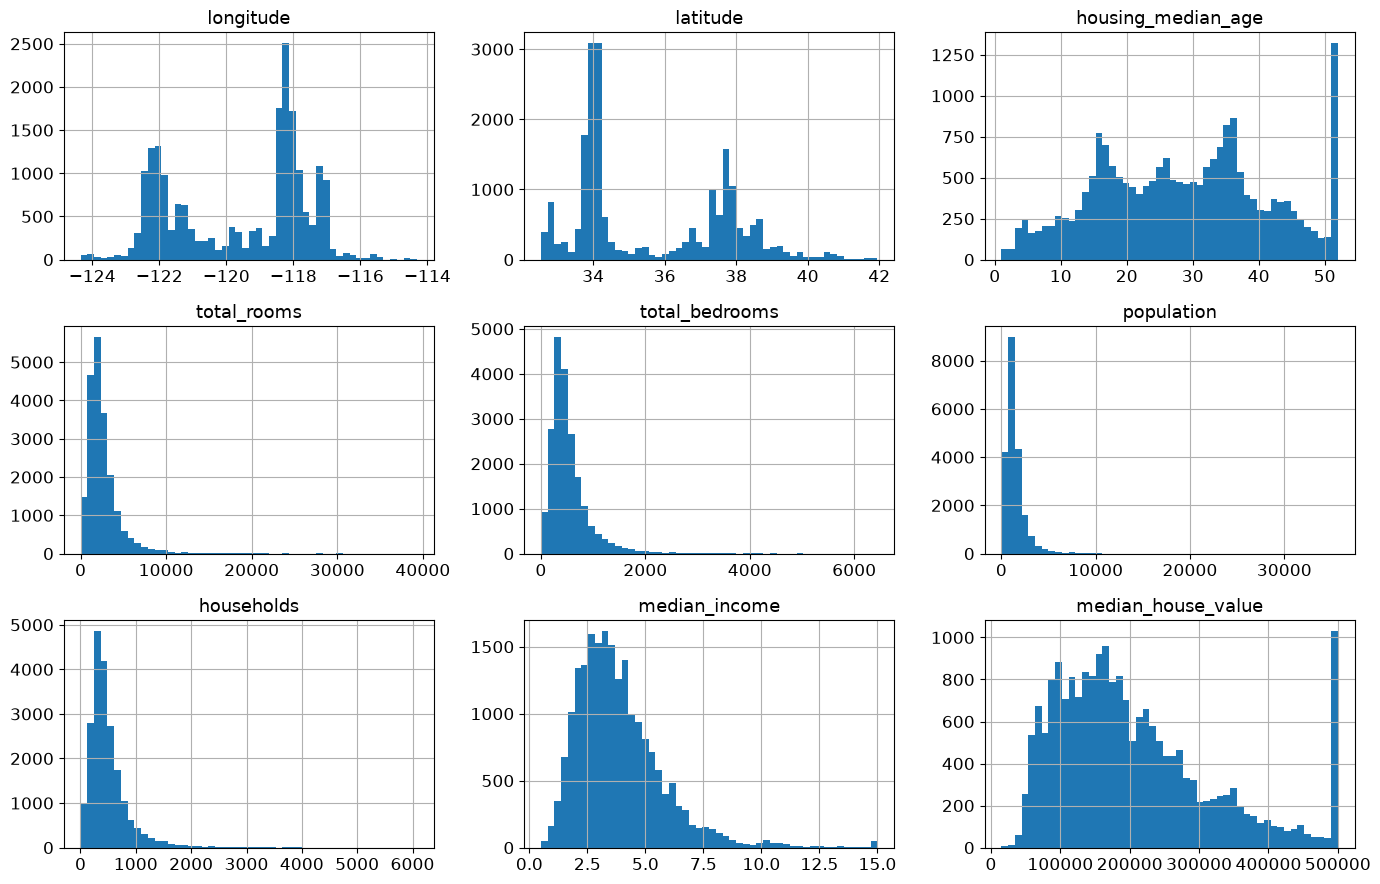

In [10]:
housing_full.hist(bins=50, figsize=(14, 9))
plt.tight_layout()
plt.show()

### 🔍 Observations importantes (et leurs conséquences)

1. **`median_income` n'est pas en dollars.** Les valeurs vont de ~0,5 à ~15 : elles ont été mises à l'échelle
   (3 = environ 30 000 $) et **plafonnées** à 15. → Pas grave, mais il faut **savoir d'où viennent ses données**.

2. **`housing_median_age` et `median_house_value` sont plafonnés** (pics tout à droite des histogrammes).
   Le plafond de `median_house_value` à 500 000 dollars est **un vrai problème** car c'est notre **cible** : le modèle
   pourrait apprendre que « les prix ne dépassent jamais 500 000 dollars ». Deux options :
   - récupérer les vrais prix pour ces districts ;
   - ou **retirer ces districts** (du train *et* du test).
   → Il faut demander à l'équipe en aval si elle a besoin de prix au-delà de 500 000 dollars. Dans le livre on les garde.

3. **Échelles très différentes** (`total_rooms` va jusqu'à ~40 000, `median_income` jusqu'à 15).
   → Il faudra **mettre à l'échelle** (*feature scaling*), étape 5.

4. **Distributions asymétriques (*skewed*, « à longue queue droite »)** : beaucoup de petites valeurs, quelques très
   grandes. Beaucoup d'algorithmes n'aiment pas ça. → On les **transformera** (logarithme), étape 5.

---
# Étape 3 — Créer un jeu de test 🔒

### 🎯 Pourquoi maintenant, *avant* même d'explorer ?
Ça paraît bizarre de mettre des données de côté si tôt. Mais ton cerveau est un excellent détecteur de motifs…
**trop** excellent : si tu regardes le jeu de test, tu risques de choisir (inconsciemment) un modèle qui
marche bien *sur ces données-là*. Résultat : ton estimation de la performance sera **trop optimiste** et le modèle
décevra en production. C'est ce qu'on appelle le **biais de *data snooping*** (« fouiner dans les données »).

**Règle d'or :** on met ~20 % des données de côté **maintenant**, et on n'y touche **qu'à la toute fin**.

## 3.1 Méthode naïve : mélanger et couper (pour comprendre)

In [9]:
def shuffle_and_split_data(data, test_ratio, rng):
    shuffled_indices = rng.permutation(len(data))     # les indices 0..n-1 dans un ordre aléatoire
    test_set_size = int(len(data) * test_ratio)
    test_indices = shuffled_indices[:test_set_size]   # les premiers -> test
    train_indices = shuffled_indices[test_set_size:]  # le reste -> entraînement
    return data.iloc[train_indices], data.iloc[test_indices]

train_set, test_set = shuffle_and_split_data(housing_full, 0.2, np.random.default_rng(RANDOM_STATE))
print(len(train_set), "en entraînement,", len(test_set), "en test")

16512 en entraînement, 4128 en test


⚠️ **Problème :** si on relance sans graine, on obtient un découpage différent → au fil du temps, ton algorithme
(et toi) finit par voir **tout** le jeu de données. Fixer la graine aide, mais casse dès que **de nouvelles données
arrivent** (les indices changent).

## 3.2 La méthode « standard » : `train_test_split`
Scikit-Learn fournit une fonction qui fait la même chose, avec une graine.

In [12]:
from sklearn.model_selection import train_test_split

train_set, test_set = train_test_split(housing_full, test_size=0.2, random_state=RANDOM_STATE)
len(train_set), len(test_set)

(16512, 4128)

## 3.3 Méthode choisie : l'échantillonnage **stratifié** 🎯

### 🎯 Pourquoi ?
Un découpage purement aléatoire fonctionne bien sur de **gros** jeux de données. Sur 20 000 lignes, on peut
tomber par malchance sur un jeu de test **non représentatif**.

Analogie : un sondage sur 1 000 personnes dans un pays à 51 % de femmes doit contenir ~510 femmes.
Si on tire au hasard, on peut en avoir 490 ou 540 → **biais**. On découpe donc la population en **strates**
(groupes) et on tire **la bonne proportion dans chaque strate**.

Ici, les experts nous disent que **le revenu médian est très important** pour prédire le prix.
On veut donc que le jeu de test ait **la même répartition de revenus** que l'ensemble.

### 🛠️ Méthode
1. Le revenu est continu → on crée une **catégorie de revenu** `income_cat` (5 tranches) avec `pd.cut`.
   On choisit des tranches assez larges pour que **chaque strate ait assez d'exemples**.
2. On découpe avec `train_test_split(..., stratify=income_cat)`.

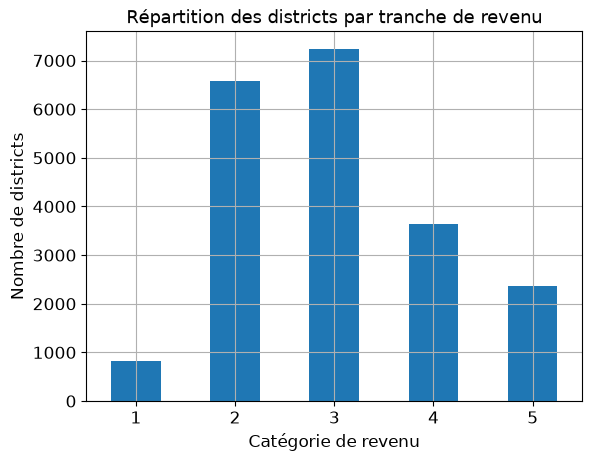

In [13]:
housing_full["income_cat"] = pd.cut(housing_full["median_income"],
                                    bins=[0., 1.5, 3.0, 4.5, 6., np.inf],
                                    labels=[1, 2, 3, 4, 5])

housing_full["income_cat"].value_counts().sort_index().plot.bar(rot=0, grid=True)
plt.xlabel("Catégorie de revenu"); plt.ylabel("Nombre de districts")
plt.title("Répartition des districts par tranche de revenu")
plt.show()

In [14]:
strat_train_set, strat_test_set = train_test_split(
    housing_full, test_size=0.2, stratify=housing_full["income_cat"], random_state=RANDOM_STATE)

# Comparons les proportions : ensemble complet vs test stratifié vs test aléatoire
def income_cat_proportions(data):
    return data["income_cat"].value_counts() / len(data)

_, rand_test_set = train_test_split(housing_full, test_size=0.2, random_state=RANDOM_STATE)

compare_props = pd.DataFrame({
    "Ensemble (%)": income_cat_proportions(housing_full),
    "Stratifié (%)": income_cat_proportions(strat_test_set),
    "Aléatoire (%)": income_cat_proportions(rand_test_set),
}).sort_index()
compare_props["Erreur stratifié (%)"] = (compare_props["Stratifié (%)"] / compare_props["Ensemble (%)"] - 1)
compare_props["Erreur aléatoire (%)"] = (compare_props["Aléatoire (%)"] / compare_props["Ensemble (%)"] - 1)
(compare_props * 100).round(2)

,Ensemble (%),Stratifié (%),Aléatoire (%),Erreur stratifié (%),Erreur aléatoire (%)
income_cat,,,,,
1,3.98,4.00,4.24,0.36,6.45
2,31.88,31.88,30.74,-0.02,-3.59
3,35.06,35.05,34.52,-0.01,-1.53
4,17.63,17.64,18.41,0.03,4.42
5,11.44,11.43,12.09,-0.08,5.63


👉 Le jeu de test **stratifié** a presque exactement les mêmes proportions que l'ensemble (erreurs proches de 0 %),
alors que le découpage **aléatoire** peut s'écarter de plusieurs pourcents sur certaines tranches.

### 🔁 Alternatives et ⚖️ pourquoi pas
| Alternative | Quand c'est mieux | Pourquoi pas ici |
|---|---|---|
| **Découpage aléatoire simple** | Très gros jeux de données (des millions de lignes) | Notre jeu est petit : risque réel de biais. |
| **Découpage par hachage d'un identifiant** (on hache l'ID de chaque ligne, et on met en test si le hash < 20 %) | Les données **sont mises à jour** régulièrement : une ligne reste toujours du même côté | Le jeu est figé (recensement 1990). Et il n'y a pas d'ID stable (on pourrait combiner latitude + longitude). |
| **`StratifiedShuffleSplit`** | Quand on veut **plusieurs** découpages stratifiés différents (ex. pour la validation croisée) | On n'en veut qu'un seul : `train_test_split(stratify=...)` est plus simple. |
| **Découpage temporel** (train = passé, test = futur) | Données qui évoluent dans le temps (séries temporelles, prévisions) | Un seul recensement, pas de dimension temporelle. |

La colonne `income_cat` n'a servi qu'au découpage : on la **supprime** pour retrouver les données d'origine.

In [13]:
for set_ in (strat_train_set, strat_test_set):
    set_.drop("income_cat", axis=1, inplace=True)

housing_full = housing_full.drop("income_cat", axis=1)
print("Train :", strat_train_set.shape, " Test :", strat_test_set.shape)

Train : (16512, 10)  Test : (4128, 10)


---
# Étape 4 — Explorer et visualiser les données 🔍

### 🎯 Pourquoi ?
Comprendre les données pour **trouver des idées** : quelles variables comptent, quelles transformations
pourraient aider, quelles anomalies nettoyer.

⚠️ On explore **uniquement le jeu d'entraînement** (le test est sous scellés). On travaille sur une **copie** pour
pouvoir tout casser sans risque.

In [15]:
housing = strat_train_set.copy()

## 4.1 Visualiser les données géographiques
Comme on a la latitude et la longitude, on peut dessiner une « carte ». Le paramètre `alpha=0.2` rend les points
semi-transparents : là où ils se superposent, la couleur est plus foncée → on voit **la densité**.

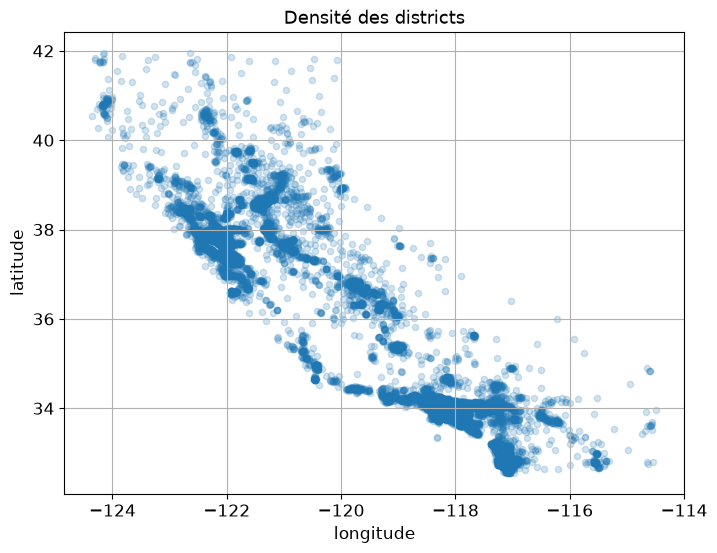

In [16]:
housing.plot(kind="scatter", x="longitude", y="latitude", grid=True, alpha=0.2, figsize=(8, 6))
plt.title("Densité des districts")
plt.show()

On reconnaît la Californie ! Les zones denses : la baie de San Francisco, Los Angeles, San Diego, et la vallée centrale.

Ajoutons deux informations :
- la **taille** de chaque cercle (`s`) = la **population** du district ;
- la **couleur** (`c`) = le **prix** (bleu = pas cher, rouge = cher), avec la palette `jet`.

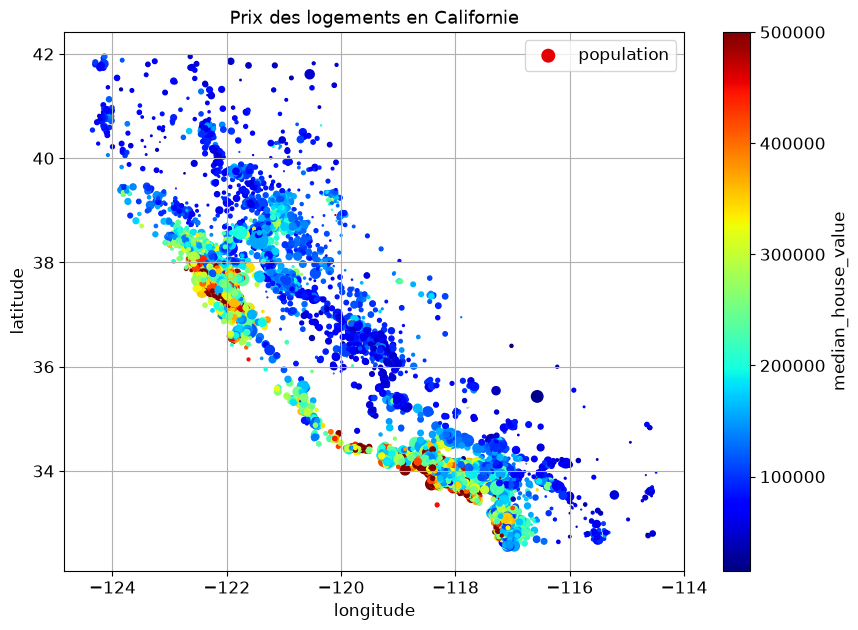

In [17]:
housing.plot(kind="scatter", x="longitude", y="latitude", grid=True,
             s=housing["population"] / 100, label="population",
             c="median_house_value", cmap="jet", colorbar=True,
             legend=True, sharex=False, figsize=(10, 7))
plt.title("Prix des logements en Californie")
plt.show()

**Ce que dit cette carte :** les prix dépendent fortement de la **localisation** (proximité de l'océan) et de la
**densité de population**. → Idée pour plus tard : un algorithme de *clustering* pour détecter les grands centres
urbains et mesurer la proximité de chaque district à ces centres (on le fera à l'étape 5 !).

## 4.2 Chercher des corrélations

### 🛠️ Méthode : le coefficient de corrélation de Pearson
Il va de **−1 à +1** :
- proche de **+1** : quand l'un monte, l'autre monte (relation linéaire positive) ;
- proche de **−1** : quand l'un monte, l'autre descend ;
- proche de **0** : **pas de relation *linéaire*** (⚠️ il peut y avoir une relation non linéaire !).

In [18]:
corr_matrix = housing.corr(numeric_only=True)  # numeric_only : on ignore la colonne texte
corr_matrix["median_house_value"].sort_values(ascending=False)

median_house_value    1.000000
median_income         0.688380
total_rooms           0.137455
housing_median_age    0.102175
households            0.071426
total_bedrooms        0.054635
population           -0.020153
longitude            -0.050859
latitude             -0.139584
Name: median_house_value, dtype: float64

👉 **`median_income` est de loin la variable la plus corrélée au prix (~0,69)**. Les experts avaient raison.
La latitude est légèrement négative : les prix baissent un peu quand on va vers le nord.

Une autre façon de voir les corrélations : la **matrice de nuages de points** (`scatter_matrix`), qui trace chaque
variable contre chaque autre. Avec 11 colonnes, ça ferait 121 graphiques → on se limite aux plus prometteuses.

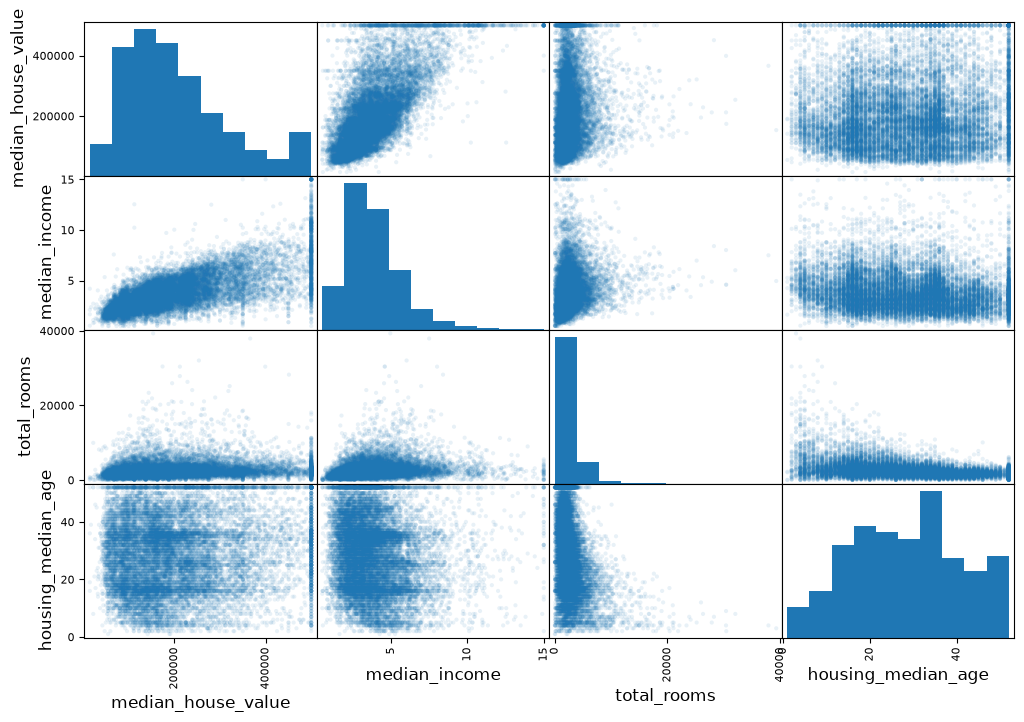

In [19]:
from pandas.plotting import scatter_matrix

attributes = ["median_house_value", "median_income", "total_rooms", "housing_median_age"]
scatter_matrix(housing[attributes], figsize=(12, 8), alpha=0.1)
plt.show()

Zoomons sur la relation la plus prometteuse : revenu ↔ prix.

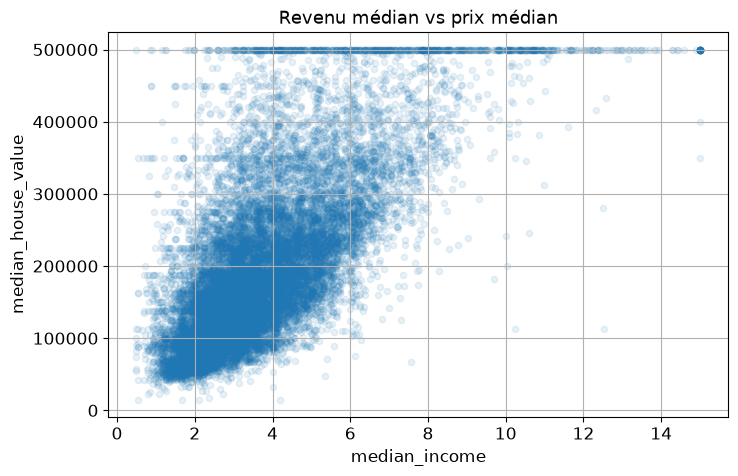

In [20]:
housing.plot(kind="scatter", x="median_income", y="median_house_value", alpha=0.1, grid=True, figsize=(8, 5))
plt.title("Revenu médian vs prix médian")
plt.show()

**Observations :**
1. La corrélation est forte : la tendance montante est nette.
2. La **ligne horizontale à 500 000 $** = le plafond vu plus tôt.
3. On devine d'autres **lignes horizontales moins visibles** vers 450 000 $, 350 000 $, 280 000 $…
   Ce sont des « bizarreries » dans les données. On pourrait **retirer ces districts** pour éviter que le modèle
   apprenne ces artefacts.

### 🔁 Alternatives à la corrélation de Pearson et ⚖️ pourquoi pas
| Alternative | Ce qu'elle mesure | Pourquoi pas ici (en premier) |
|---|---|---|
| **Corrélation de Spearman** (`housing.corr(method="spearman")`) | Relation **monotone** (pas forcément linéaire), robuste aux outliers | Très bonne idée en complément ! Pearson est la plus simple et la plus courante pour une 1re exploration. |
| **Information mutuelle** (`sklearn.feature_selection.mutual_info_regression`) | **N'importe quelle** dépendance, même non monotone | Plus difficile à interpréter (pas de signe, pas d'échelle −1/+1). |
| **Seaborn `pairplot`** | Comme `scatter_matrix`, en plus joli | Ajoute une dépendance ; pandas suffit. |

## 4.3 Combiner des attributs (*feature engineering*)

### 🎯 Pourquoi ?
Certaines colonnes brutes ne sont **pas très parlantes**. `total_rooms` (nombre total de pièces du district) n'aide
pas beaucoup si on ne sait pas combien il y a de foyers. Ce qui est intéressant, c'est le **nombre de pièces
*par logement***. On crée donc des **ratios** :

In [21]:
housing["rooms_per_house"] = housing["total_rooms"] / housing["households"]       # pièces par logement
housing["bedrooms_ratio"] = housing["total_bedrooms"] / housing["total_rooms"]    # part de chambres
housing["people_per_house"] = housing["population"] / housing["households"]       # personnes par logement

corr_matrix = housing.corr(numeric_only=True)
corr_matrix["median_house_value"].sort_values(ascending=False)

median_house_value    1.000000
median_income         0.688380
rooms_per_house       0.143663
total_rooms           0.137455
housing_median_age    0.102175
households            0.071426
total_bedrooms        0.054635
population           -0.020153
people_per_house     -0.038224
longitude            -0.050859
latitude             -0.139584
bedrooms_ratio       -0.256397
Name: median_house_value, dtype: float64

🎉 **`bedrooms_ratio` (≈ −0,26) est bien plus corrélé au prix que `total_bedrooms` ou `total_rooms`** :
les maisons avec une plus faible proportion de chambres (donc plus de salons, bureaux…) sont plus chères.
`rooms_per_house` est aussi plus informatif que `total_rooms`.

> 💡 Cette exploration n'a pas besoin d'être exhaustive. L'idée est d'avoir **de premières intuitions** pour
> obtenir vite un premier prototype correct. Le ML est **itératif** : on reviendra explorer plus tard.

---
# Étape 5 — Préparer les données pour les algorithmes 🧹

### 🎯 Pourquoi écrire des **fonctions / pipelines** plutôt que transformer à la main ?
- Pouvoir **reproduire** les transformations sur n'importe quel jeu (ex. le jeu de test, ou de nouvelles données en production).
- Se construire petit à petit une **bibliothèque de transformations** réutilisable.
- Tester facilement **plusieurs combinaisons** de transformations (et même les optimiser automatiquement !).

On repart d'un jeu d'entraînement propre et on **sépare les entrées (X) de la cible (y)** : on ne veut pas
forcément appliquer les mêmes transformations aux deux.

In [22]:
housing = strat_train_set.drop("median_house_value", axis=1)   # X : les caractéristiques (features)
housing_labels = strat_train_set["median_house_value"].copy()  # y : les étiquettes (labels)
housing.shape, housing_labels.shape

((16512, 10), (16512,))

## 5.1 Nettoyer les données : les valeurs manquantes

### 🎯 Pourquoi ?
La plupart des algorithmes de ML **ne savent pas gérer les valeurs manquantes** (`NaN`) et plantent.
`total_bedrooms` en a. Il y a 3 options :

In [23]:
null_rows_idx = housing.isnull().any(axis=1)
print("Nombre de lignes avec au moins une valeur manquante :", null_rows_idx.sum())

# Option 1 : supprimer les districts concernés
option1 = housing.loc[null_rows_idx].dropna(subset=["total_bedrooms"])
print("Option 1 (supprimer les lignes)   -> il reste", len(option1), "lignes sur ces", null_rows_idx.sum())

# Option 2 : supprimer toute la colonne
option2 = housing.loc[null_rows_idx].drop("total_bedrooms", axis=1)
print("Option 2 (supprimer la colonne)   -> colonnes restantes :", option2.shape[1])

# Option 3 : remplacer par une valeur (ici la médiane) = « imputation »
median = housing["total_bedrooms"].median()
option3 = housing.loc[null_rows_idx].fillna({"total_bedrooms": median})
print("Option 3 (imputer par la médiane) -> médiane utilisée :", median)

Nombre de lignes avec au moins une valeur manquante : 168
Option 1 (supprimer les lignes)   -> il reste 0 lignes sur ces 168
Option 2 (supprimer la colonne)   -> colonnes restantes : 9
Option 3 (imputer par la médiane) -> médiane utilisée : 434.0


### 🛠️ Méthode choisie : option 3, avec `SimpleImputer(strategy="median")`
On garde toutes les lignes et toutes les colonnes. On utilise la **médiane** plutôt que la moyenne car elle est
**robuste** aux valeurs extrêmes (nos distributions ont de longues queues : la moyenne serait tirée vers le haut).

Pourquoi `SimpleImputer` plutôt que `fillna` de pandas ?
👉 L'imputer **mémorise** la médiane calculée sur le **jeu d'entraînement** (méthode `fit`). On pourra ensuite
appliquer **la même valeur** au jeu de test et aux nouvelles données (méthode `transform`). C'est crucial :
on ne doit **jamais** recalculer la médiane sur le jeu de test (ce serait une fuite d'information).

> 📘 **L'API de Scikit-Learn en 3 mots** (à retenir, c'est partout !) :
> - **`fit(X)`** : *apprendre* des paramètres à partir des données (ici : les médianes). Les paramètres appris finissent par `_` (ex. `statistics_`).
> - **`transform(X)`** : *appliquer* la transformation avec les paramètres appris.
> - **`fit_transform(X)`** : les deux d'un coup (sur le jeu d'entraînement).
> - Les modèles ont **`predict(X)`** à la place de `transform`.

In [24]:
from sklearn.impute import SimpleImputer

imputer = SimpleImputer(strategy="median")
housing_num = housing.select_dtypes(include=[np.number])  # la médiane n'a de sens que pour les nombres

imputer.fit(housing_num)
print("Médianes apprises :", imputer.statistics_)
print("Vérification      :", housing_num.median().values)

X = imputer.transform(housing_num)                         # renvoie un tableau NumPy
housing_tr = pd.DataFrame(X, columns=housing_num.columns, index=housing_num.index)
print("Valeurs manquantes restantes :", housing_tr.isnull().sum().sum())

Médianes apprises : [-118.51     34.26     29.     2125.      434.     1167.      408.
    3.5385]
Vérification      : [-118.51     34.26     29.     2125.      434.     1167.      408.
    3.5385]
Valeurs manquantes restantes : 0


On a appliqué l'imputer à **toutes** les colonnes numériques, pas seulement `total_bedrooms` : en production, il
pourrait manquer des valeurs ailleurs. Mieux vaut être prêt.

### 🔁 Alternatives et ⚖️ pourquoi pas
| Alternative | Quand c'est mieux | Pourquoi pas ici |
|---|---|---|
| **Supprimer les lignes** (`dropna`) | Très peu de lignes concernées *et* manque aléatoire | On perdrait des données ; et en production on ne peut pas « refuser » de prédire un district. |
| **Supprimer la colonne** | La colonne est presque vide ou inutile | `total_bedrooms` sert à calculer `bedrooms_ratio`, très utile ! |
| **Moyenne** (`strategy="mean"`) | Distribution symétrique, sans outliers | Nos distributions sont asymétriques → la médiane est plus fiable. |
| **Valeur la plus fréquente** (`"most_frequent"`) | Variables **catégorielles** | On l'utilisera justement pour `ocean_proximity` ! |
| **`KNNImputer`** (moyenne des k voisins les plus proches) | Les valeurs manquantes peuvent être devinées à partir de districts similaires | Plus lent, et seulement 1 % de manquants : gain probablement faible. |
| **`IterativeImputer`** (un modèle prédit chaque colonne manquante à partir des autres) | Beaucoup de manquants corrélés aux autres colonnes | Encore expérimental dans Scikit-Learn, plus complexe. |
| **`add_indicator=True`** (ajoute une colonne « était manquant ? ») | Quand le **fait même** qu'une valeur manque est informatif | Ici le manque semble aléatoire. Bonne idée à tester plus tard. |

## 5.2 Gérer le texte et les variables catégorielles

### 🎯 Pourquoi ?
Les algorithmes ne comprennent **que des nombres**. Il faut convertir `ocean_proximity` (texte) en nombres.

In [25]:
housing_cat = housing[["ocean_proximity"]]   # double crochets -> un DataFrame (2D), attendu par Scikit-Learn
housing_cat.head(8)

,ocean_proximity
13096,NEAR BAY
14973,<1H OCEAN
3785,INLAND
14689,INLAND
20507,NEAR OCEAN
1286,INLAND
18078,<1H OCEAN
4396,NEAR BAY


### Tentative 1 : `OrdinalEncoder` (une catégorie = un entier)

In [26]:
from sklearn.preprocessing import OrdinalEncoder

ordinal_encoder = OrdinalEncoder()
housing_cat_encoded = ordinal_encoder.fit_transform(housing_cat)
print(ordinal_encoder.categories_)
print(housing_cat_encoded[:8].ravel())

[array(['<1H OCEAN', 'INLAND', 'ISLAND', 'NEAR BAY', 'NEAR OCEAN'],
      dtype=object)]
[3. 0. 1. 1. 4. 1. 0. 3.]


⚠️ **Problème :** l'algorithme va croire que deux valeurs proches (0 et 1) sont **plus similaires** que deux valeurs
éloignées (0 et 4). Ici l'ordre est **arbitraire** (alphabétique) : `<1H OCEAN`=0 et `NEAR OCEAN`=4 sont pourtant
assez similaires ! L'encodage ordinal n'est adapté **que si les catégories ont un ordre naturel**
(ex. « mauvais < moyen < bon < excellent »).

### 🛠️ Méthode choisie : le **one-hot encoding** (`OneHotEncoder`)
On crée **une colonne binaire par catégorie** : 1 si le district est dans cette catégorie, 0 sinon.
Une seule colonne vaut 1 (« hot »), les autres 0 (« cold »).

| ocean_proximity | <1H OCEAN | INLAND | ISLAND | NEAR BAY | NEAR OCEAN |
|---|---|---|---|---|---|
| INLAND | 0 | **1** | 0 | 0 | 0 |
| NEAR BAY | 0 | 0 | 0 | **1** | 0 |

In [27]:
from sklearn.preprocessing import OneHotEncoder

cat_encoder = OneHotEncoder()
housing_cat_1hot = cat_encoder.fit_transform(housing_cat)
print(type(housing_cat_1hot))        # une matrice « creuse » (sparse)
print(cat_encoder.categories_)
housing_cat_1hot.toarray()[:5]

<class 'scipy.sparse._csr.csr_matrix'>
[array(['<1H OCEAN', 'INLAND', 'ISLAND', 'NEAR BAY', 'NEAR OCEAN'],
      dtype=object)]


array([[0., 0., 0., 1., 0.],
       [1., 0., 0., 0., 0.],
       [0., 1., 0., 0., 0.],
       [0., 1., 0., 0., 0.],
       [0., 0., 0., 0., 1.]])

💡 Le résultat est une **matrice creuse** (*sparse matrix*) : comme il y a surtout des 0, on ne stocke que la
position des 1. Avec des milliers de catégories, ça économise énormément de mémoire. `.toarray()` la convertit
en tableau normal.

### Pourquoi `OneHotEncoder` plutôt que `pd.get_dummies()` de pandas ?
`get_dummies` fait la même chose en apparence, **mais il ne mémorise pas les catégories** :

In [28]:
df_test_unknown = pd.DataFrame({"ocean_proximity": ["<2H OCEAN", "ISLAND"]})  # "<2H OCEAN" n'existe pas !
print("get_dummies crée des colonnes différentes :")
print(pd.get_dummies(df_test_unknown))

cat_encoder.handle_unknown = "ignore"   # catégorie inconnue -> que des 0 au lieu d'une erreur
print("\nOneHotEncoder garde toujours les mêmes 5 colonnes :")
pd.DataFrame(cat_encoder.transform(df_test_unknown).toarray(),
             columns=cat_encoder.get_feature_names_out(), index=df_test_unknown.index)

get_dummies crée des colonnes différentes :
   ocean_proximity_<2H OCEAN  ocean_proximity_ISLAND
0                       True                   False
1                      False                    True

OneHotEncoder garde toujours les mêmes 5 colonnes :


,ocean_proximity_<1H OCEAN,ocean_proximity_INLAND,ocean_proximity_ISLAND,ocean_proximity_NEAR BAY,ocean_proximity_NEAR OCEAN
0,0.0,0.0,0.0,0.0,0.0
1,0.0,0.0,1.0,0.0,0.0


👉 `get_dummies` génère des colonnes **différentes** selon les données qu'on lui donne → le modèle recevrait des
entrées incohérentes. `OneHotEncoder` produit **toujours les mêmes colonnes, dans le même ordre**.

### 🔁 Alternatives et ⚖️ pourquoi pas
| Alternative | Quand c'est mieux | Pourquoi pas ici |
|---|---|---|
| **`OrdinalEncoder`** | Catégories **ordonnées** (tailles S/M/L, niveaux d'étude) | Nos catégories n'ont pas d'ordre naturel. (Les modèles à arbres le tolèrent assez bien, cependant.) |
| **`pd.get_dummies`** | Exploration rapide dans pandas | Ne mémorise pas les catégories → incohérent entre train, test et production. |
| **`TargetEncoder`** (remplace chaque catégorie par le prix moyen de cette catégorie) | **Beaucoup** de catégories (ex. 10 000 codes postaux) : le one-hot créerait 10 000 colonnes | 5 catégories seulement : le one-hot est simple et parfait. |
| **Embeddings** (vecteurs appris par un réseau de neurones) | Très nombreuses catégories, avec du deep learning | On verra ça plus loin dans le livre (réseaux de neurones). |

## 5.3 Mise à l'échelle des caractéristiques (*feature scaling*)

### 🎯 Pourquoi ?
Les algorithmes de ML fonctionnent mal quand les variables ont des **échelles très différentes**
(`total_rooms` ≈ 6 à 39 000, `median_income` ≈ 0,5 à 15). Un modèle basé sur des distances ou sur la descente de
gradient donnerait trop de poids aux grandes valeurs.

⚠️ Comme pour l'imputer : on fait `fit` **uniquement sur le jeu d'entraînement**.

Deux méthodes principales :

In [29]:
from sklearn.preprocessing import MinMaxScaler, StandardScaler

# Min-max : ramène chaque colonne entre -1 et 1 (ou 0 et 1 par défaut)
min_max_scaler = MinMaxScaler(feature_range=(-1, 1))
housing_num_min_max_scaled = min_max_scaler.fit_transform(housing_num)

# Standardisation : (valeur - moyenne) / écart-type  -> moyenne 0, écart-type 1
std_scaler = StandardScaler()
housing_num_std_scaled = std_scaler.fit_transform(housing_num)

# (np.nanmin / np.nanmax : on ignore les valeurs manquantes de total_bedrooms)
pd.DataFrame({"min-max (min)": np.nanmin(housing_num_min_max_scaled, axis=0).round(2),
              "min-max (max)": np.nanmax(housing_num_min_max_scaled, axis=0).round(2),
              "standard (moyenne)": np.nanmean(housing_num_std_scaled, axis=0).round(2),
              "standard (écart-type)": np.nanstd(housing_num_std_scaled, axis=0).round(2)},
             index=housing_num.columns)

,min-max (min),min-max (max),standard (moyenne),standard (écart-type)
longitude,-1.0,1.0,-0.0,1.0
latitude,-1.0,1.0,0.0,1.0
housing_median_age,-1.0,1.0,-0.0,1.0
total_rooms,-1.0,1.0,-0.0,1.0
total_bedrooms,-1.0,1.0,0.0,1.0
population,-1.0,1.0,0.0,1.0
households,-1.0,1.0,0.0,1.0
median_income,-1.0,1.0,0.0,1.0


### 🛠️ Méthode choisie : la **standardisation** (`StandardScaler`)
| | Min-max | Standardisation |
|---|---|---|
| Résultat | Valeurs dans un intervalle fixe ([0, 1] ou [−1, 1]) | Moyenne 0, écart-type 1, pas de bornes |
| Sensibilité aux outliers | **Forte** : une seule valeur énorme écrase toutes les autres vers 0 | **Faible** |
| Idéal pour | Réseaux de neurones (qui aiment des entrées bornées), images (pixels 0–255) | La plupart des cas, surtout avec des outliers |

Nos données ont des outliers (`total_rooms` max ≈ 39 000 alors que la médiane ≈ 2 100) → **standardisation**.

## 5.4 Transformer les distributions à longue queue (logarithme)

### 🎯 Pourquoi ?
Une variable à longue queue reste « tassée » même après standardisation : la plupart des valeurs sont serrées,
quelques-unes très loin. Les modèles (surtout linéaires) préfèrent des distributions **à peu près symétriques**
(en cloche). Le **logarithme** « écrase » les grandes valeurs et étire les petites.

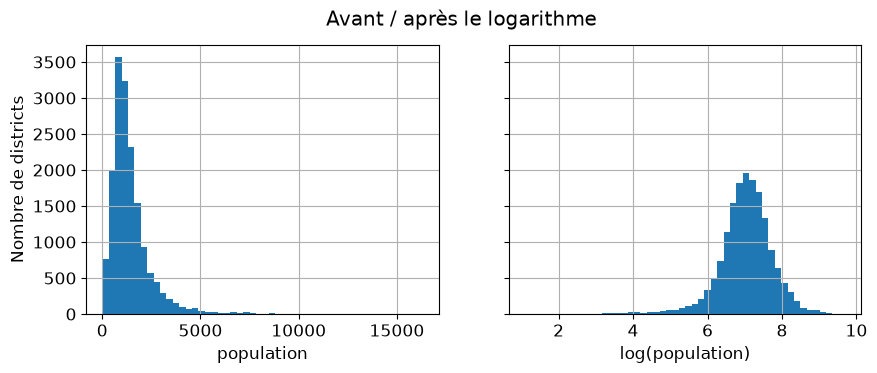

In [30]:
fig, axs = plt.subplots(1, 2, figsize=(10, 3.5), sharey=True)
housing["population"].hist(ax=axs[0], bins=50)
housing["population"].apply(np.log).hist(ax=axs[1], bins=50)
axs[0].set_xlabel("population"); axs[1].set_xlabel("log(population)")
axs[0].set_ylabel("Nombre de districts")
plt.suptitle("Avant / après le logarithme")
plt.show()

👉 Après le log, la distribution ressemble à une **cloche** (gaussienne). Bien mieux !

### 🔁 Autres transformations possibles et ⚖️ quand les utiliser
| Transformation | Idée | Quand l'utiliser |
|---|---|---|
| **Logarithme** ✅ | log(x) | Longue queue droite, valeurs > 0 (populations, revenus, prix) |
| **Racine carrée / puissance** | x^0,5… | Queue moins lourde que pour le log |
| **`PowerTransformer`** (Box-Cox / Yeo-Johnson) | Trouve automatiquement la meilleure puissance | Quand on ne sait pas laquelle choisir ; un peu moins lisible |
| **`QuantileTransformer`** | Force une distribution uniforme ou normale | Distributions très bizarres ; mais déforme les distances |
| **Découpage en tranches (*bucketizing*)** | Remplace la valeur par son numéro de tranche (percentile) | Distributions **multimodales** (plusieurs pics) |
| **Similarité RBF** | Mesure à quel point la valeur est proche d'un mode (pic) | Ex. `housing_median_age` a un pic vers 35 ans → démonstration ci-dessous |

### Démonstration (avancé) : similarité RBF à un pic
Une **RBF gaussienne** vaut 1 quand la valeur est exactement 35, et décroît vers 0 en s'éloignant.
`gamma` contrôle la vitesse de décroissance.

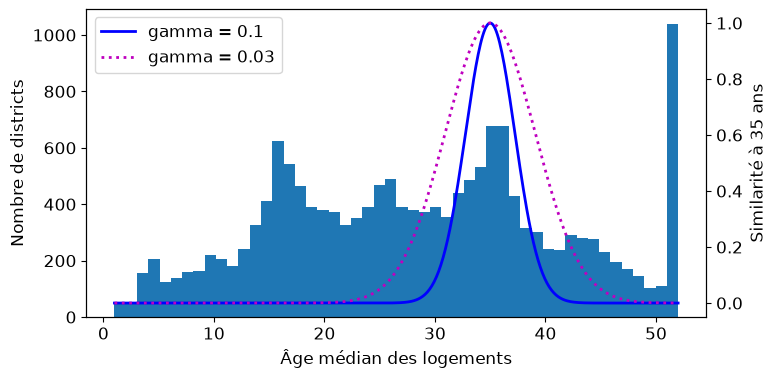

In [31]:
from sklearn.metrics.pairwise import rbf_kernel

ages = np.linspace(housing["housing_median_age"].min(), housing["housing_median_age"].max(), 500).reshape(-1, 1)
fig, ax1 = plt.subplots(figsize=(8, 4))
ax1.hist(housing["housing_median_age"], bins=50)
ax1.set_xlabel("Âge médian des logements"); ax1.set_ylabel("Nombre de districts")
ax2 = ax1.twinx()
for gamma, style in [(0.1, "b-"), (0.03, "m:")]:
    ax2.plot(ages, rbf_kernel(ages, [[35]], gamma=gamma), style, linewidth=2, label=f"gamma = {gamma}")
ax2.set_ylabel("Similarité à 35 ans"); ax2.legend(loc="upper left")
plt.show()

## 5.5 Et la cible (y) ? (avancé)

Si la **cible** avait une longue queue, on pourrait aussi la passer au log. Mais alors le modèle prédirait des
log(prix) : il faut penser à revenir en dollars (`np.exp`). `TransformedTargetRegressor` fait tout ça
automatiquement. On ne l'utilise pas dans la suite (la cible n'a pas une queue énorme), mais voici à quoi ça ressemble :

In [32]:
from sklearn.compose import TransformedTargetRegressor
from sklearn.linear_model import LinearRegression

model = TransformedTargetRegressor(LinearRegression(), transformer=StandardScaler())
model.fit(housing[["median_income"]], housing_labels)
model.predict(housing[["median_income"]].iloc[:5])   # les prédictions sont bien en dollars

array([131997.15275877, 299359.35844434, 146023.37185694, 138840.33653057,
       192016.61557639])

## 5.6 Transformateurs personnalisés

### 🎯 Pourquoi ?
Scikit-Learn ne peut pas tout prévoir : nos **ratios** (`rooms_per_house`…) ou le **log** doivent être intégrés à
la chaîne de traitement pour être appliqués automatiquement aux nouvelles données.

### 🛠️ Méthode 1 : `FunctionTransformer` (pour une transformation **sans apprentissage**)
On lui donne simplement une fonction.

In [33]:
from sklearn.preprocessing import FunctionTransformer

log_transformer = FunctionTransformer(np.log, inverse_func=np.exp)
log_pop = log_transformer.transform(housing[["population"]])

ratio_transformer = FunctionTransformer(lambda X: X[:, [0]] / X[:, [1]])
ratio_transformer.transform(np.array([[1., 2.], [3., 4.]]))   # -> [[0.5], [0.75]]

array([[0.5 ],
       [0.75]])

### 🛠️ Méthode 2 : une **classe** personnalisée (pour une transformation **qui apprend**) — *avancé*

Souvenir de la carte : les prix dépendent de la proximité aux **grands centres**. Idée :
1. Utiliser **K-means** (algorithme de *clustering*, chapitre 8) pour trouver automatiquement **10 centres**
   géographiques où les districts sont regroupés. → C'est l'étape **`fit`** (apprentissage).
2. Pour chaque district, calculer sa **similarité RBF** à chacun des 10 centres (1 = juste à côté, 0 = très loin).
   → C'est l'étape **`transform`**. On obtient 10 nouvelles colonnes.

Pour qu'une classe soit compatible avec Scikit-Learn, il suffit de :
- hériter de **`BaseEstimator`** (donne `get_params`/`set_params`, utiles pour l'optimisation automatique) et
  **`TransformerMixin`** (donne `fit_transform` gratuitement) ;
- écrire `__init__` (sans `*args`/`**kwargs`), `fit` (qui **retourne `self`**) et `transform`.

In [34]:
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.cluster import KMeans

class ClusterSimilarity(BaseEstimator, TransformerMixin):
    def __init__(self, n_clusters=10, gamma=1.0, random_state=None):
        self.n_clusters = n_clusters        # combien de centres chercher
        self.gamma = gamma                  # vitesse de décroissance de la similarité
        self.random_state = random_state    # K-means utilise du hasard -> reproductibilité

    def fit(self, X, y=None, sample_weight=None):   # y=None obligatoire pour les pipelines, même si inutilisé
        self.kmeans_ = KMeans(self.n_clusters, random_state=self.random_state)
        self.kmeans_.fit(X, sample_weight=sample_weight)
        return self                                 # toujours retourner self !

    def transform(self, X):
        return rbf_kernel(X, self.kmeans_.cluster_centers_, gamma=self.gamma)

    def get_feature_names_out(self, names=None):
        return [f"Cluster {i} similarity" for i in range(self.n_clusters)]

cluster_simil = ClusterSimilarity(n_clusters=10, gamma=1., random_state=RANDOM_STATE)
similarities = cluster_simil.fit_transform(housing[["latitude", "longitude"]],
                                           sample_weight=housing_labels)  # centres attirés vers les districts chers
similarities[:3].round(2)

array([[0.  , 0.98, 0.  , 0.  , 0.  , 0.  , 0.13, 0.55, 0.  , 0.56],
       [0.64, 0.  , 0.11, 0.04, 0.  , 0.  , 0.  , 0.  , 0.99, 0.  ],
       [0.  , 0.65, 0.  , 0.  , 0.01, 0.  , 0.49, 0.59, 0.  , 0.28]])

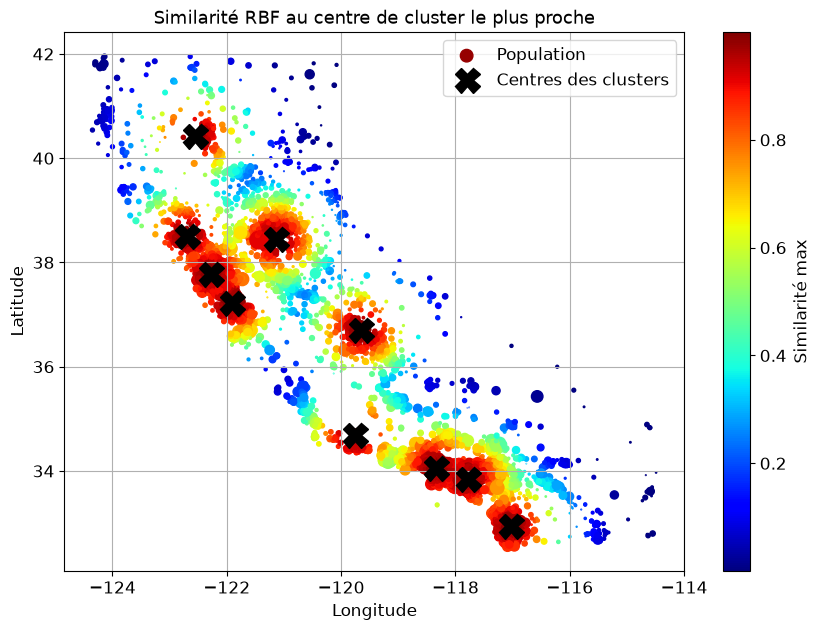

In [35]:
# Visualisons les 10 centres trouvés
housing_renamed = housing.rename(columns={"latitude": "Latitude", "longitude": "Longitude"})
housing_renamed["Similarité max"] = similarities.max(axis=1)
housing_renamed.plot(kind="scatter", x="Longitude", y="Latitude", grid=True,
                     s=housing_renamed["population"] / 100, label="Population",
                     c="Similarité max", cmap="jet", colorbar=True, legend=True, sharex=False, figsize=(10, 7))
centers = cluster_simil.kmeans_.cluster_centers_
plt.plot(centers[:, 1], centers[:, 0], linestyle="", color="black", marker="X", markersize=18,
         label="Centres des clusters")
plt.legend(loc="upper right")
plt.title("Similarité RBF au centre de cluster le plus proche")
plt.show()

### 🔁 Alternatives à `ClusterSimilarity` et ⚖️ pourquoi pas
| Alternative | Quand c'est mieux | Pourquoi pas ici |
|---|---|---|
| **Garder latitude/longitude brutes** | Modèles à arbres (ils découpent l'espace tout seuls) | Un modèle linéaire ne peut pas exploiter « proche de San Francisco » à partir de coordonnées brutes. |
| **Distance aux grandes villes connues** (LA, SF…) | Quand on a une connaissance métier précise | Il faudrait choisir les villes à la main ; K-means les trouve automatiquement. |
| **Numéro de cluster en one-hot** | Simple à comprendre | Effet « escalier » brutal aux frontières ; la similarité RBF est continue. |

## 5.7 Les **pipelines** : tout enchaîner proprement

### 🎯 Pourquoi ?
On a maintenant plein de transformations à appliquer **dans le bon ordre** (imputer → ratio → log → standardiser…),
à des **colonnes différentes**. Les faire à la main, c'est la garantie d'oublier une étape sur le jeu de test.

### 🛠️ Méthode : `Pipeline` + `ColumnTransformer`
- Un **`Pipeline`** enchaîne des étapes : la sortie de l'une devient l'entrée de la suivante.
  Quand on appelle `pipeline.fit(X)`, il fait `fit_transform` sur chaque étape, puis `fit` sur la dernière.
- Un **`ColumnTransformer`** applique des transformations **différentes à des colonnes différentes**, puis
  **concatène** les résultats côte à côte.

In [36]:
from sklearn.pipeline import Pipeline, make_pipeline

# Version longue : on nomme chaque étape (noms sans "__")
num_pipeline = Pipeline([
    ("impute", SimpleImputer(strategy="median")),
    ("standardize", StandardScaler()),
])

# Version courte : make_pipeline nomme les étapes automatiquement ("simpleimputer", "standardscaler")
num_pipeline = make_pipeline(SimpleImputer(strategy="median"), StandardScaler())

sklearn.set_config(display="diagram")   # affichage interactif des pipelines dans Jupyter
num_pipeline

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('simpleimputer', ...), ('standardscaler', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"strategy strategy: str or Callable, default='mean'The imputation strategy.- If ""mean"", then replace missing values using the mean along each column. Can only be used with numeric data.- If ""median"", then replace missing values using the median along each column. Can only be used with numeric data.- If ""most_frequent"", then replace missing using the most frequent value along each column. Can be used with strings or numeric data. If there is more than one such value, only the smallest is returned.- If ""constant"", then replace missing values with fill_value. Can be used with strings or numeric data.- If an instance of Callable, then replace missing values using the scalar statistic returned by running the callable over a dense 1d array containing non-missing values of each column... versionadded:: 0.20 strategy=""constant"" for fixed value imputation... versionadded:: 1.5 strategy=callable for custom value imputation.",'median'
,"missing_values missing_values: int, float, str, np.nan, None or pandas.NA, default=np.nanThe placeholder for the missing values. All occurrences of`missing_values` will be imputed. For pandas' dataframes withnullable integer dtypes with missing values, `missing_values`can be set to either `np.nan` or `pd.NA`.",nan
,"fill_value fill_value: str or numerical value, default=NoneWhen strategy == ""constant"", `fill_value` is used to replace alloccurrences of missing_values. For string or object data types,`fill_value` must be a string.If `None`, `fill_value` will be 0 when imputing numericaldata and ""missing_value"" for strings or object data types.",None
,"copy copy: bool, default=TrueIf True, a copy of X will be created. If False, imputation willbe done in-place whenever possible. Note that, in the following cases,a new copy will always be made, even if `copy=False`:- If `X` is not an array of floating values;- If `X` is encoded as a CSR matrix;- If `add_indicator=True`.",True
,"add_indicator add_indicator: bool, default=FalseIf True, a :class:`MissingIndicator` transform will stack onto outputof the imputer's transform. This allows a predictive estimato

In [37]:
housing_num_prepared = num_pipeline.fit_transform(housing_num)
pd.DataFrame(housing_num_prepared, columns=num_pipeline.get_feature_names_out(),
             index=housing_num.index).head(3).round(2)

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income
13096,-1.42,1.01,1.86,0.31,1.37,0.14,1.39,-0.94
14973,0.60,-0.70,0.91,-0.31,-0.44,-0.69,-0.37,1.17
3785,-1.20,1.28,0.35,-0.71,-0.76,-0.79,-0.78,-0.76


Maintenant, le **pipeline de prétraitement complet**. Récapitulons ce qu'il fait et **pourquoi** :

| Étape | Colonnes | Pourquoi |
|---|---|---|
| Imputation par la **médiane** | Numériques | Les algorithmes n'acceptent pas les `NaN` (5.1) |
| Imputation par la **valeur la plus fréquente** + **one-hot** | `ocean_proximity` | Les algorithmes veulent des nombres (5.2) |
| **3 ratios** : `bedrooms_ratio`, `rooms_per_house`, `people_per_house` | Comptes totaux | Mieux corrélés au prix (4.3) |
| **10 similarités aux clusters** | latitude, longitude | Plus exploitables que les coordonnées brutes (5.6) |
| **Logarithme** | Colonnes à longue queue | Distributions plus symétriques (5.4) |
| **Standardisation** | Toutes les numériques | Mêmes échelles pour toutes les variables (5.3) |

In [38]:
from sklearn.compose import ColumnTransformer, make_column_selector

def column_ratio(X):
    return X[:, [0]] / X[:, [1]]

def ratio_name(function_transformer, feature_names_in):
    return ["ratio"]  # nom de la colonne produite

def ratio_pipeline():
    return make_pipeline(
        SimpleImputer(strategy="median"),
        FunctionTransformer(column_ratio, feature_names_out=ratio_name),
        StandardScaler())

log_pipeline = make_pipeline(
    SimpleImputer(strategy="median"),
    FunctionTransformer(np.log, feature_names_out="one-to-one"),
    StandardScaler())

cat_pipeline = make_pipeline(
    SimpleImputer(strategy="most_frequent"),
    OneHotEncoder(handle_unknown="ignore"))

cluster_simil = ClusterSimilarity(n_clusters=10, gamma=1., random_state=RANDOM_STATE)
default_num_pipeline = make_pipeline(SimpleImputer(strategy="median"), StandardScaler())

preprocessing = ColumnTransformer([
        ("bedrooms", ratio_pipeline(), ["total_bedrooms", "total_rooms"]),
        ("rooms_per_house", ratio_pipeline(), ["total_rooms", "households"]),
        ("people_per_house", ratio_pipeline(), ["population", "households"]),
        ("log", log_pipeline, ["total_bedrooms", "total_rooms", "population", "households", "median_income"]),
        ("geo", cluster_simil, ["latitude", "longitude"]),
        # dtype_exclude=np.number : sélectionne les colonnes texte (fonctionne avec pandas 2 ET pandas 3)
        ("cat", cat_pipeline, make_column_selector(dtype_exclude=np.number)),
    ],
    remainder=default_num_pipeline)  # colonne restante : housing_median_age

preprocessing

,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('bedrooms', ...), ('rooms_per_house', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",Pipeline(step...ardScaler())])
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field na

In [39]:
housing_prepared = preprocessing.fit_transform(housing)
print("Forme après préparation :", housing_prepared.shape)   # 16 512 lignes, 24 colonnes
preprocessing.get_feature_names_out()

Forme après préparation : (16512, 29)


array(['bedrooms__ratio', 'rooms_per_house__ratio',
       'people_per_house__ratio', 'log__total_bedrooms',
       'log__total_rooms', 'log__population', 'log__households',
       'log__median_income', 'geo__Cluster 0 similarity',
       'geo__Cluster 1 similarity', 'geo__Cluster 2 similarity',
       'geo__Cluster 3 similarity', 'geo__Cluster 4 similarity',
       'geo__Cluster 5 similarity', 'geo__Cluster 6 similarity',
       'geo__Cluster 7 similarity', 'geo__Cluster 8 similarity',
       'geo__Cluster 9 similarity', 'cat__ocean_proximity_<1H OCEAN',
       'cat__ocean_proximity_INLAND', 'cat__ocean_proximity_ISLAND',
       'cat__ocean_proximity_NEAR BAY', 'cat__ocean_proximity_NEAR OCEAN',
       'cat__income_cat_1', 'cat__income_cat_2', 'cat__income_cat_3',
       'cat__income_cat_4', 'cat__income_cat_5',
       'remainder__housing_median_age'], dtype=object)

🎉 En **une seule ligne** (`preprocessing.fit_transform(housing)`), toutes les transformations sont appliquées.
Et surtout, plus tard, `preprocessing.transform(nouvelles_donnees)` appliquera **exactement les mêmes** (mêmes
médianes, mêmes centres de clusters, mêmes moyennes…).

### 🔁 Alternatives aux pipelines Scikit-Learn et ⚖️ pourquoi pas
| Alternative | Quand c'est mieux | Pourquoi pas ici |
|---|---|---|
| **Transformations manuelles avec pandas** | Exploration rapide | Risque d'oublis et de **fuites de données** (*data leakage*) quand on fait de la validation croisée. |
| **`make_column_transformer`** | Version courte (noms automatiques) | On préfère nommer nos étapes (`"geo"`, `"log"`…) : ça servira à l'étape 7 pour les régler. |
| **Outils dédiés** (Feature-engine, pandas `pipe`, Spark ML…) | Très gros volumes ou équipes data | Scikit-Learn suffit largement ici. |

---
# Étape 6 — Choisir et entraîner un modèle 🤖

Enfin ! Grâce au travail précédent, entraîner un modèle prend… 2 lignes.

## 6.1 Premier essai : la régression linéaire

### 🎯 Pourquoi commencer par un modèle simple ?
Un modèle simple donne une **référence** (*baseline*) : si un modèle compliqué ne fait pas mieux, il ne sert à rien.
La régression linéaire cherche la meilleure **droite** (en fait un hyperplan) : prix ≈ a₁·x₁ + a₂·x₂ + … + b.

In [40]:
from sklearn.linear_model import LinearRegression

lin_reg = make_pipeline(preprocessing, LinearRegression())
lin_reg.fit(housing, housing_labels)

housing_predictions = lin_reg.predict(housing)
print("Prédictions :", housing_predictions[:5].round(-2))   # arrondi à la centaine
print("Vrais prix  :", housing_labels.iloc[:5].values)

Prédictions : [255500. 428500. 131000.  92500. 323000.]
Vrais prix  : [458300. 483800. 101700.  96100. 361800.]


In [41]:
from sklearn.metrics import root_mean_squared_error

lin_rmse = root_mean_squared_error(housing_labels, housing_predictions)
print(f"RMSE de la régression linéaire (sur le train) : {lin_rmse:,.0f} $")

RMSE de la régression linéaire (sur le train) : 64,684 $


Une erreur typique de **~68 000 $**, alors que la plupart des prix sont entre 120 000 $ et 265 000 $ : pas terrible.

### 📉 Diagnostic : **sous-apprentissage** (*underfitting*)
Le modèle **se trompe déjà beaucoup sur les données qu'il a vues** pendant l'entraînement. Il est trop simple pour
capturer la réalité (les relations ne sont pas toutes linéaires). Trois remèdes :
1. un **modèle plus puissant** ;
2. de **meilleures features** ;
3. **réduire les contraintes** du modèle (régularisation — il n'y en a pas ici).

Essayons l'option 1.

## 6.2 Deuxième essai : l'arbre de décision
Un **arbre de décision** pose une série de questions (« revenu > 5 ? », « INLAND ? »…) et peut capturer des
relations **non linéaires** complexes (chapitre 5/6 du livre).

In [42]:
from sklearn.tree import DecisionTreeRegressor

tree_reg = make_pipeline(preprocessing, DecisionTreeRegressor(random_state=RANDOM_STATE))
tree_reg.fit(housing, housing_labels)

housing_predictions = tree_reg.predict(housing)
tree_rmse = root_mean_squared_error(housing_labels, housing_predictions)
print(f"RMSE de l'arbre de décision (sur le train) : {tree_rmse:,.0f} $")

RMSE de l'arbre de décision (sur le train) : 0 $


**0 $ d'erreur ?!** 🤨 Un modèle parfait ? Bien sûr que non : il a **appris par cœur** les données d'entraînement.

### 📈 Diagnostic : **sur-apprentissage** (*overfitting*)
Comme un élève qui apprend les réponses de l'examen blanc par cœur sans comprendre : il aura 20/20 à l'examen
blanc et échouera au vrai. Pour le savoir, il faut évaluer le modèle sur des données **qu'il n'a pas vues**.

…Mais on ne veut pas toucher au jeu de test ! Solution : la **validation croisée**.

## 6.3 Évaluer correctement avec la **validation croisée** (*cross-validation*)

### 🛠️ Méthode : la validation croisée en K plis (*K-fold*)
On découpe le jeu d'entraînement en **10 morceaux** (*folds*). Puis, 10 fois :
- on entraîne le modèle sur **9 morceaux** ;
- on l'évalue sur **le 10ᵉ** (qu'il n'a pas vu).

On obtient **10 scores** → une moyenne **et** une idée de la **variabilité** (écart-type).

```
Pli 1 : [TEST][train][train][train][train][train][train][train][train][train]
Pli 2 : [train][TEST][train][train][train][train][train][train][train][train]
...
Pli 10: [train][train][train][train][train][train][train][train][train][TEST]
```

> ⚠️ Scikit-Learn attend un **score** (plus grand = meilleur), pas une erreur. On utilise donc
> `"neg_root_mean_squared_error"` (la RMSE **négative**) et on remet le signe `-` devant.

In [43]:
from sklearn.model_selection import cross_val_score

tree_rmses = -cross_val_score(tree_reg, housing, housing_labels,
                              scoring="neg_root_mean_squared_error", cv=10)
pd.Series(tree_rmses).describe().round(0)

count       10.0
mean     67057.0
std       1869.0
min      65166.0
25%      65686.0
50%      66384.0
75%      67762.0
max      70801.0
dtype: float64

👉 En validation croisée, l'arbre a une RMSE d'environ **67 000 $** : **à peine mieux que la régression linéaire** !
L'écart énorme entre l'erreur d'entraînement (0) et l'erreur de validation (~67 000) confirme le sur-apprentissage.

### 🔁 Alternatives à la validation croisée K-fold et ⚖️ pourquoi pas
| Alternative | Quand c'est mieux | Pourquoi pas ici |
|---|---|---|
| **Un seul jeu de validation** (*holdout*) | Énormes jeux de données, ou modèles très longs à entraîner (deep learning) | Notre jeu est petit : un seul découpage donne une estimation bruitée. |
| **Moins de plis** (`cv=3` ou `5`) | Pour aller plus vite | 10 plis = estimation plus fiable ; ici c'est assez rapide. (On utilisera `cv=3` pour la recherche d'hyperparamètres.) |
| **Leave-One-Out** (autant de plis que de lignes) | Très petits jeux (< 100 lignes) | 16 512 entraînements : beaucoup trop lent. |
| **`TimeSeriesSplit`** | Données temporelles | Pas de notion de temps ici. |

## 6.4 Troisième essai : la **forêt aléatoire** 🌲🌲🌲
Une **forêt aléatoire** (*Random Forest*) entraîne **beaucoup d'arbres** (100 par défaut), chacun sur un
sous-échantillon aléatoire des données et des features, puis **fait la moyenne** de leurs prédictions. Les erreurs
des arbres individuels se compensent : c'est l'**apprentissage d'ensemble** (chapitre 6/7).

⏳ *Cette cellule prend un peu de temps (10 forêts de 100 arbres) : 1 à 3 minutes selon ton ordinateur.*

In [44]:
from sklearn.ensemble import RandomForestRegressor

forest_reg = make_pipeline(preprocessing, RandomForestRegressor(random_state=RANDOM_STATE))
forest_rmses = -cross_val_score(forest_reg, housing, housing_labels,
                                scoring="neg_root_mean_squared_error", cv=10, n_jobs=-1)  # n_jobs=-1 : tous les cœurs CPU
pd.Series(forest_rmses).describe().round(0)

count       10.0
mean     47127.0
std       1062.0
min      45362.0
25%      46730.0
50%      47198.0
75%      47514.0
max      49358.0
dtype: float64

👉 **~47 000 $** : beaucoup mieux ! La forêt aléatoire est très prometteuse.

Mais vérifions le sur-apprentissage : comparons l'erreur **sur le train** à l'erreur **en validation**.

In [45]:
forest_reg.fit(housing, housing_labels)
forest_train_rmse = root_mean_squared_error(housing_labels, forest_reg.predict(housing))
print(f"RMSE train      : {forest_train_rmse:,.0f} $")
print(f"RMSE validation : {forest_rmses.mean():,.0f} $")

RMSE train      : 17,521 $
RMSE validation : 47,127 $


L'erreur d'entraînement (~17 000 $) est **bien plus basse** que celle de validation (~47 000 $) → le modèle
**sur-apprend encore pas mal**. Solutions : simplifier/contraindre le modèle (régularisation), ou plus de données.

> 💡 **Conseil du livre :** à ce stade, il faudrait essayer **beaucoup d'autres modèles** (SVM, réseaux de neurones…)
> **sans passer trop de temps à régler les hyperparamètres**, pour présélectionner 2 à 5 modèles prometteurs.

## 6.5 Bonus : une alternative moderne, le **Gradient Boosting**

Pour illustrer, testons `HistGradientBoostingRegressor` : au lieu de faire la moyenne d'arbres indépendants
(forêt), le *boosting* entraîne les arbres **les uns après les autres**, chacun corrigeant les erreurs du précédent.
C'est souvent le meilleur choix sur des **données tabulaires** (tableaux), et c'est **très rapide**.

In [46]:
from sklearn.ensemble import HistGradientBoostingRegressor

hgb_reg = make_pipeline(preprocessing, HistGradientBoostingRegressor(random_state=RANDOM_STATE))
hgb_rmses = -cross_val_score(hgb_reg, housing, housing_labels,
                             scoring="neg_root_mean_squared_error", cv=10, n_jobs=-1)
pd.Series(hgb_rmses).describe().round(0)

count       10.0
mean     45435.0
std       1155.0
min      43791.0
25%      44945.0
50%      45407.0
75%      45835.0
max      48072.0
dtype: float64

In [47]:
# Tableau récapitulatif des modèles testés (tous évalués de la même façon : validation croisée 10 plis)
lin_rmses = -cross_val_score(lin_reg, housing, housing_labels,
                             scoring="neg_root_mean_squared_error", cv=10)
all_rmses = {"Régression linéaire": lin_rmses, "Arbre de décision": tree_rmses,
             "Forêt aléatoire": forest_rmses, "Gradient Boosting (HGB)": hgb_rmses}
pd.DataFrame({"RMSE validation (moyenne)": {k: v.mean() for k, v in all_rmses.items()},
              "Écart-type": {k: v.std() for k, v in all_rmses.items()}}).round(0)

,RMSE validation (moyenne),Écart-type
Régression linéaire,65444.0,2700.0
Arbre de décision,67057.0,1773.0
Forêt aléatoire,47127.0,1007.0
Gradient Boosting (HGB),45435.0,1096.0


### 🔁 Récapitulatif : quel modèle choisir ? ⚖️
| Modèle | Points forts | Points faibles | Verdict ici |
|---|---|---|---|
| **Régression linéaire** | Simple, rapide, interprétable | Ne capture que des relations linéaires → sous-apprend | Bonne *baseline* |
| **Arbre de décision** | Non linéaire, interprétable | Sur-apprend énormément | Éliminé |
| **Forêt aléatoire** ✅ | Robuste, peu de réglages, donne l'importance des features | Lent, fichier lourd, sur-apprend un peu | **Choix du livre** → on l'affine à l'étape 7 |
| **Gradient Boosting (HGB)** | Souvent le plus précis sur des tableaux, très rapide | Plus d'hyperparamètres sensibles | Excellente alternative : compare les scores ci-dessus ! |
| **SVM (`SVR`)** | Bon sur petits jeux bien préparés | Lent au-delà de ~10 000 lignes, réglages délicats | Exercice 1 du chapitre |
| **k plus proches voisins** | Très intuitif | Lent en prédiction, sensible aux échelles | À essayer en exercice |
| **Réseau de neurones (PyTorch)** | Très puissant sur images, texte, son | Sur un petit tableau, rarement mieux que le boosting | Vu plus loin dans le livre |

Pour rester fidèle au livre, **on continue avec la forêt aléatoire**. (Tu peux refaire l'étape 7 avec HGB en exercice !)

---
# Étape 7 — Affiner le modèle 🎛️

## 7.1 Recherche sur grille (`GridSearchCV`)

### 🎯 Pourquoi ?
Chaque modèle a des **hyperparamètres** : des réglages qu'on choisit **avant** l'entraînement (ex. nombre de
clusters, nombre de features examinées à chaque nœud d'un arbre…). À ne pas confondre avec les **paramètres**,
que le modèle apprend tout seul (ex. les coefficients de la régression).

Les régler à la main est fastidieux. `GridSearchCV` essaie **toutes les combinaisons** d'une liste et évalue chacune
par **validation croisée**.

### 🛠️ Méthode
On peut régler n'importe quel hyperparamètre **à l'intérieur du pipeline**, grâce aux noms d'étapes séparés
par **deux underscores** `__` :

`"preprocessing__geo__n_clusters"` = dans l'étape `preprocessing` → le transformateur `geo` → son paramètre `n_clusters`.

C'est puissant : on règle **en même temps** le prétraitement et le modèle !

⏳ *15 combinaisons × 3 plis = 45 entraînements de forêts : quelques minutes.*

In [48]:
from sklearn.model_selection import GridSearchCV

full_pipeline = Pipeline([
    ("preprocessing", preprocessing),
    ("random_forest", RandomForestRegressor(random_state=RANDOM_STATE)),
])

param_grid = [
    {"preprocessing__geo__n_clusters": [5, 8, 10],
     "random_forest__max_features": [4, 6, 8]},       # 3 x 3 = 9 combinaisons
    {"preprocessing__geo__n_clusters": [10, 15],
     "random_forest__max_features": [6, 8, 10]},      # 2 x 3 = 6 combinaisons
]

grid_search = GridSearchCV(full_pipeline, param_grid, cv=3,
                           scoring="neg_root_mean_squared_error", n_jobs=-1)
grid_search.fit(housing, housing_labels)
print("Meilleurs hyperparamètres :", grid_search.best_params_)
print(f"Meilleure RMSE (validation) : {-grid_search.best_score_:,.0f} $")

Meilleurs hyperparamètres : {'preprocessing__geo__n_clusters': 15, 'random_forest__max_features': 6}
Meilleure RMSE (validation) : 45,336 $


In [49]:
cv_res = pd.DataFrame(grid_search.cv_results_)
cv_res = cv_res.sort_values(by="mean_test_score", ascending=False)
cv_res = cv_res[["param_preprocessing__geo__n_clusters", "param_random_forest__max_features",
                 "split0_test_score", "split1_test_score", "split2_test_score", "mean_test_score"]]
cv_res.columns = ["n_clusters", "max_features", "pli 1", "pli 2", "pli 3", "moyenne"]
score_cols = ["pli 1", "pli 2", "pli 3", "moyenne"]
cv_res[score_cols] = -cv_res[score_cols].round().astype(np.int64)   # on repasse en RMSE positive
cv_res.head()

,n_clusters,max_features,pli 1,pli 2,pli 3,moyenne
12,15,6,44656,45348,46004,45336
13,15,8,44873,45154,46030,45352
14,15,10,45181,45222,45927,45443
7,10,6,46133,46189,47123,46482
9,10,6,46133,46189,47123,46482


💡 Note : le meilleur `n_clusters` (15) est **à la limite** de la grille. Ça suggère d'essayer des valeurs plus
grandes ! C'est exactement ce que fait la recherche aléatoire ci-dessous.

## 7.2 Recherche aléatoire (`RandomizedSearchCV`) — méthode retenue

### 🎯 Pourquoi ?
La grille devient vite **énorme** : 6 hyperparamètres × 10 valeurs = **1 million** de combinaisons !
La recherche aléatoire tire **un nombre fixé** de combinaisons au hasard (ici 10), dans des **distributions**.

**Avantages :**
- Pour un hyperparamètre continu, elle explore **10 valeurs différentes** au lieu des 3 listées dans une grille.
- Si un hyperparamètre **ne sert à rien**, il ne fait pas exploser le temps de calcul.
- Tu **contrôles le budget** (nombre d'itérations).

In [50]:
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import randint

param_distribs = {"preprocessing__geo__n_clusters": randint(low=3, high=50),   # entier entre 3 et 49
                  "random_forest__max_features": randint(low=2, high=20)}

rnd_search = RandomizedSearchCV(
    full_pipeline, param_distributions=param_distribs, n_iter=10, cv=3,
    scoring="neg_root_mean_squared_error", random_state=RANDOM_STATE, n_jobs=-1)
rnd_search.fit(housing, housing_labels)

print("Meilleurs hyperparamètres :", rnd_search.best_params_)
print(f"Meilleure RMSE (validation) : {-rnd_search.best_score_:,.0f} $")

Meilleurs hyperparamètres : {'preprocessing__geo__n_clusters': 45, 'random_forest__max_features': 9}
Meilleure RMSE (validation) : 42,954 $


### 🔁 Alternatives pour régler les hyperparamètres et ⚖️ pourquoi pas
| Méthode | Principe | Quand c'est mieux | Pourquoi pas ici |
|---|---|---|---|
| **Réglage manuel** | On essaie à la main | Pour comprendre l'effet d'un paramètre | Fastidieux, non systématique |
| **`GridSearchCV`** | Toutes les combinaisons | Peu d'hyperparamètres, peu de valeurs | Explose combinatoirement |
| **`RandomizedSearchCV`** ✅ | Combinaisons tirées au hasard | Espace de recherche grand | — (choisi) |
| **`HalvingRandomSearchCV`** | Beaucoup de candidats sur peu de données, puis on garde les meilleurs et on leur donne plus de données | Gagner du temps sur de gros espaces | Encore « expérimental » dans Scikit-Learn |
| **Optimisation bayésienne** (Optuna, scikit-optimize) | Un modèle apprend où se trouvent les bons réglages et y concentre la recherche | Entraînements coûteux (deep learning) | Bibliothèque supplémentaire ; vu plus loin dans le livre |

## 7.3 Analyser le meilleur modèle

### Importance des features
Une forêt aléatoire peut indiquer **quelles variables l'aident le plus** à prédire.

In [51]:
final_model = rnd_search.best_estimator_   # le meilleur pipeline complet (prétraitement + forêt)
feature_importances = final_model["random_forest"].feature_importances_
importances = pd.Series(feature_importances,
                        index=final_model["preprocessing"].get_feature_names_out()).sort_values(ascending=False)
importances.head(15).round(3)

log__median_income             0.137
cat__income_cat_5              0.082
cat__ocean_proximity_INLAND    0.067
bedrooms__ratio                0.054
people_per_house__ratio        0.048
cat__income_cat_2              0.045
rooms_per_house__ratio         0.036
geo__Cluster 30 similarity     0.028
geo__Cluster 9 similarity      0.021
geo__Cluster 3 similarity      0.018
geo__Cluster 36 similarity     0.018
geo__Cluster 25 similarity     0.017
geo__Cluster 18 similarity     0.016
geo__Cluster 32 similarity     0.016
geo__Cluster 1 similarity      0.015
dtype: float64

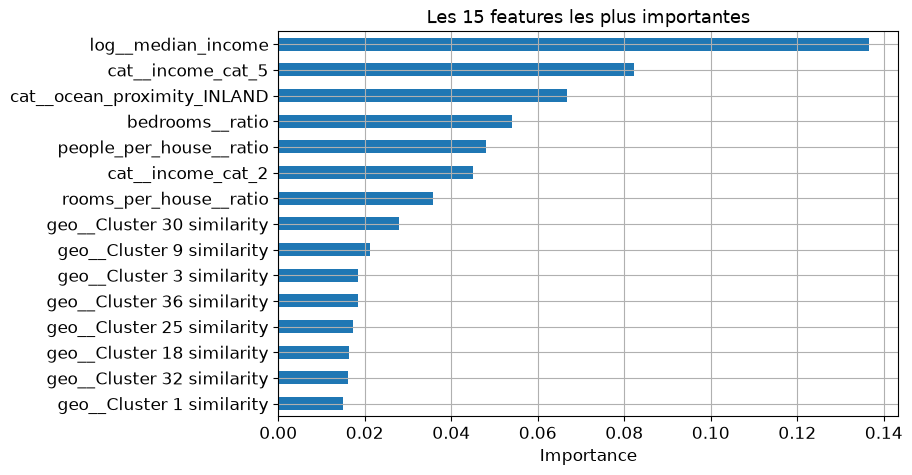

In [52]:
importances.head(15).sort_values().plot.barh(figsize=(8, 5), grid=True)
plt.xlabel("Importance"); plt.title("Les 15 features les plus importantes")
plt.show()

👉 **Le revenu médian (`log__median_income`) est de loin le facteur n°1**, suivi de « est-ce à l'intérieur des
terres (`INLAND`) ? » et des ratios qu'on a créés. Notre *feature engineering* a payé !
On remarque aussi que seule la catégorie `INLAND` d'`ocean_proximity` semble vraiment utile : on pourrait essayer
de supprimer les autres (`SelectFromModel` peut le faire automatiquement).

### Analyse des erreurs et équité (*fairness*)
Un modèle doit bien marcher **en moyenne**, mais aussi **sur chaque catégorie** de districts (riches/pauvres,
côte/intérieur…). On regarde l'erreur par groupe — **en validation croisée**, toujours pas sur le test !

In [53]:
from sklearn.model_selection import cross_val_predict

val_predictions = cross_val_predict(final_model, housing, housing_labels, cv=3, n_jobs=-1)
errors = pd.DataFrame({
    "ocean_proximity": housing["ocean_proximity"],
    "tranche_revenu": pd.cut(housing["median_income"], bins=[0., 1.5, 3.0, 4.5, 6., np.inf],
                             labels=["<1.5", "1.5-3", "3-4.5", "4.5-6", ">6"]),
    "erreur_carree": (val_predictions - housing_labels) ** 2,
})

def rmse_by(group):
    g = errors.groupby(group, observed=True)
    return pd.DataFrame({"RMSE": np.sqrt(g["erreur_carree"].mean()).round(0), "nb districts": g.size()})

display(rmse_by("ocean_proximity"))
display(rmse_by("tranche_revenu"))

,RMSE,nb districts
ocean_proximity,,
<1H OCEAN,44901.0,7274
INLAND,32668.0,5301
ISLAND,112483.0,2
NEAR BAY,47906.0,1846
NEAR OCEAN,53078.0,2089


,RMSE,nb districts
tranche_revenu,,
<1.5,51530.0,657
1.5-3,37638.0,5265
3-4.5,42576.0,5789
4.5-6,45727.0,2911
>6,49795.0,1890


👉 L'erreur n'est **pas uniforme** :
- elle est plus grande pour les tranches de revenu **extrêmes** (très pauvres et très riches — chez ces derniers,
  beaucoup de prix sont plafonnés à 500 000 $) ;
- elle est plus faible pour `INLAND`… mais c'est aussi là que les maisons sont **les moins chères** : une erreur de
  32 000 $ y pèse relativement plus lourd. Calculer une erreur **relative** (en %) par groupe serait plus juste ;
- `ISLAND` n'a que 2 districts dans le train : son chiffre ne veut rien dire statistiquement.

Dans un vrai projet, il faudrait décider si c'est acceptable avant de déployer, ou ne pas utiliser le modèle pour
certaines catégories.

---
# Étape 8 — Évaluer sur le jeu de test 🏁

### 🎯 Pourquoi seulement maintenant ?
Le jeu de test sert à estimer **la performance réelle sur des données jamais vues**, **une seule fois**, à la fin.

⚠️ **Règle d'or :** si le score déçoit, **ne retouche pas les hyperparamètres pour améliorer le score du test**.
Sinon le test devient un jeu de validation, et ton estimation redevient trop optimiste.

On utilise `predict` (et **jamais** `fit`) : le pipeline applique automatiquement le même prétraitement.

In [54]:
X_test = strat_test_set.drop("median_house_value", axis=1)
y_test = strat_test_set["median_house_value"].copy()

final_predictions = final_model.predict(X_test)
final_rmse = root_mean_squared_error(y_test, final_predictions)
print(f"RMSE finale sur le jeu de test : {final_rmse:,.0f} $")

RMSE finale sur le jeu de test : 42,204 $


### Intervalle de confiance à 95 % (avancé)
Un seul chiffre ne dit pas **à quel point il est précis**. Le **bootstrap** ré-échantillonne les erreurs du test
des milliers de fois pour estimer un intervalle où se trouve (probablement) la vraie RMSE.

In [55]:
from scipy import stats

def rmse(squared_errors):
    return np.sqrt(np.mean(squared_errors))

squared_errors = (final_predictions - y_test) ** 2
boot_result = stats.bootstrap([squared_errors], rmse, confidence_level=0.95, random_state=RANDOM_STATE)
rmse_lower, rmse_upper = boot_result.confidence_interval
print(f"Intervalle de confiance à 95 % : [{rmse_lower:,.0f} $ ; {rmse_upper:,.0f} $]")

Intervalle de confiance à 95 % : [40,288 $ ; 44,451 $]


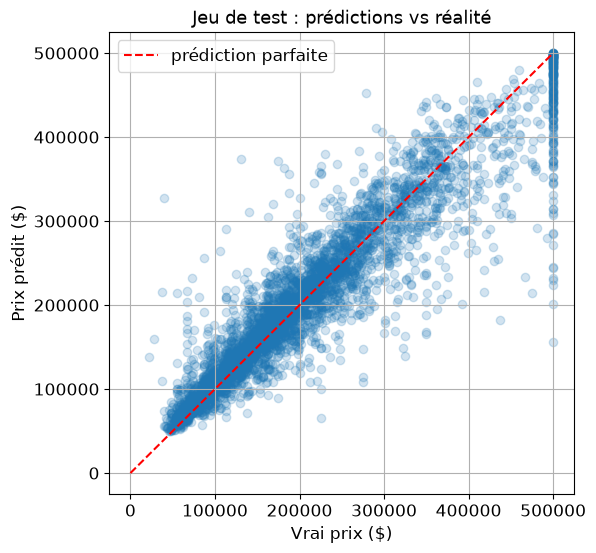

In [56]:
# Visualiser les prédictions vs les vrais prix
plt.figure(figsize=(6, 6))
plt.scatter(y_test, final_predictions, alpha=0.2)
plt.plot([0, 500_000], [0, 500_000], "r--", label="prédiction parfaite")
plt.xlabel("Vrai prix ($)"); plt.ylabel("Prix prédit ($)")
plt.title("Jeu de test : prédictions vs réalité"); plt.legend(); plt.grid(True)
plt.show()

**Interprétation :** les points suivent la diagonale rouge (bon signe). La colonne verticale à droite correspond aux
districts plafonnés à 500 000 $ : le modèle les sous-estime souvent — conséquence directe du plafonnement repéré à
l'étape 2.

Avec une erreur d'environ **41 000 $**, notre modèle est meilleur que les estimations des experts (souvent ~30 %
d'erreur), sans être parfait. Il peut libérer du temps aux experts pour des tâches plus intéressantes.

---
# Étape 9 — Lancer, surveiller et maintenir le système 🚀

## 9.1 Sauvegarder le modèle
### 🛠️ Méthode : `joblib`
On sauvegarde **le pipeline complet** (prétraitement + modèle) dans un fichier. En production, on le recharge et
on appelle `predict` sur de nouvelles données brutes.

In [56]:
import joblib

Path("models").mkdir(exist_ok=True)
joblib.dump(final_model, "models/california_housing_model.pkl")
print("Modèle sauvegardé ✅  taille :", round(Path("models/california_housing_model.pkl").stat().st_size / 1e6, 1), "Mo")
# ⚠️ ~150 Mo (une forêt de 100 arbres profonds) : trop lourd pour GitHub -> le dossier models/ est dans .gitignore

Modèle sauvegardé ✅  taille : 144.9 Mo


In [57]:
# Plus tard (ou dans un autre programme) : on recharge et on prédit
final_model_reloaded = joblib.load("models/california_housing_model.pkl")

new_data = X_test.iloc[:5]   # on fait comme si c'étaient de nouveaux districts
pd.DataFrame({"Prix prédit": final_model_reloaded.predict(new_data).round(-2),
              "Vrai prix": y_test.iloc[:5].values})

,Prix prédit,Vrai prix
0,427100.0,397700.0
1,212700.0,202900.0
2,360100.0,310000.0
3,334500.0,314300.0
4,309200.0,187500.0


⚠️ **Piège classique :** pour recharger le modèle dans **un autre script**, les fonctions et classes personnalisées
(`ClusterSimilarity`, `column_ratio`, `ratio_name`) doivent être **importables** dans ce script (par exemple placées
dans un fichier `housing_utils.py`). Sinon `joblib.load` plante.

### 🔁 Alternatives pour sauvegarder / déployer et ⚖️ pourquoi pas
| Alternative | Quand c'est mieux | Pourquoi pas ici |
|---|---|---|
| **`pickle`** (module standard) | Petits objets | `joblib` est plus efficace pour les gros tableaux NumPy (nos forêts). |
| **`skops`** | Partager un modèle de façon **sécurisée** (un `.pkl` peut exécuter du code malveillant au chargement !) | Projet perso : on ne charge que nos propres fichiers. |
| **ONNX** | Déployer dans un autre langage (C++, Java, navigateur…) | Conversion plus complexe. |
| **API web** (FastAPI / Flask) | Plusieurs applications doivent interroger le modèle | Bonne étape suivante pour ton portfolio ! |
| **Cloud** (Google Vertex AI, AWS SageMaker…) | Gros trafic, mise à l'échelle automatique | Surdimensionné pour apprendre. |

## 9.2 Surveiller et maintenir (théorie)
Un modèle **se dégrade avec le temps** (*model rot*) : le monde change (inflation, nouveaux quartiers…), et les
données qu'il voit ne ressemblent plus à celles de l'entraînement (*data drift*). Il faut donc :
- **surveiller** la performance en continu (comparer les prédictions aux vrais prix quand ils sont connus,
  ou à défaut surveiller la **distribution des entrées**) et déclencher des **alertes** ;
- **ré-entraîner régulièrement** le modèle sur des données fraîches (idéalement de façon automatisée) ;
- **garder des sauvegardes** des modèles et des jeux de données pour pouvoir **revenir en arrière** ;
- **vérifier la qualité des données entrantes** (capteur cassé, colonne manquante…).

---
# 🎓 Récapitulatif

| Étape | Ce qu'on a fait | L'idée clé à retenir |
|---|---|---|
| 1. Vue d'ensemble | Régression supervisée, métrique RMSE | **Comprendre le besoin métier avant de coder** |
| 2. Données | Téléchargement automatisé, `info`, `describe`, histogrammes | **Connaître ses données** (plafonds, unités, manquants) |
| 3. Jeu de test | Découpage **stratifié** sur le revenu | **Mettre le test de côté tout de suite** |
| 4. Exploration | Carte, corrélations, nouveaux ratios | Le revenu est roi ; les ratios aident |
| 5. Préparation | Imputation, one-hot, log, standardisation, clusters, **pipeline** | **Tout automatiser dans un pipeline** |
| 6. Modèles | Linéaire (sous-apprend) → arbre (sur-apprend) → forêt ✅ | **Valider par validation croisée** |
| 7. Affinage | Grid search, random search, importances, erreurs par groupe | Régler prétraitement **et** modèle ensemble |
| 8. Test | RMSE finale + intervalle de confiance | **Ne pas tricher avec le test** |
| 9. Production | `joblib`, surveillance, ré-entraînement | Un modèle se dégrade : il faut le surveiller |

## 📖 Mini-glossaire
- **Feature / attribut** : une variable d'entrée (une colonne de X).
- **Label / étiquette / cible** : ce qu'on veut prédire (y).
- **Sous-apprentissage** : modèle trop simple, mauvais même sur le train.
- **Sur-apprentissage** : modèle qui apprend par cœur, bon sur le train, mauvais sur de nouvelles données.
- **Hyperparamètre** : réglage choisi avant l'entraînement (≠ paramètre appris).
- **Validation croisée** : évaluer sur plusieurs découpages train/validation pour une estimation fiable.
- **Pipeline** : chaîne d'étapes de prétraitement + modèle, appliquée de façon identique partout.
- **Fuite de données (*data leakage*)** : quand une information du jeu de test/validation « fuit » dans l'entraînement.